# Toolkit financiero: demostración con datos reales

Este notebook recorre el toolkit tal como lo usaría un analista: **sin tocar ningún
adaptador concreto**. Todo se pide a los casos de uso que construye `toolkit.bootstrap`
(el *composition root*):

| Caso de uso (puerto inbound) | Se construye con | Para qué |
|---|---|---|
| `DownloadData` | `build_download_service(fuente_precios, fuente_macro)` | Descargar series de precios y macro en lote |
| `ListDocuments` | `build_document_service(fuente)` | Listar documentos regulatorios |
| `StoreSeries` | `build_storage_service(directorio, formato)` | Guardar las series en CSV o Parquet |

Contenido:

1. Puesta en marcha
2. Precios de mercado (y tolerancia a fallos)
3. El mismo contrato con otra fuente
4. Series macro sin clave (BCE, Banco Mundial)
5. FRED: última revisión frente a vintage (*look-ahead bias*)
6. Validación de peticiones
7. Documentos regulatorios (CNMV, ESMA)
8. Cartera y Monte Carlo
9. Guardar y releer las series
10. La misma descarga desde la CLI

> Necesita conexión a Internet. Las celdas que requieren una clave que no está en `.env`
> se saltan con un aviso. Las fuentes públicas a veces tardan o fallan: el toolkit lo
> registra como error de esa serie y sigue con el resto.

## 1. Puesta en marcha

In [1]:
import logging
import os
import subprocess
import sys
import tempfile
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from toolkit import bootstrap
from toolkit.bootstrap import build_document_service, build_download_service, build_storage_service
from toolkit.domain.documents import DocumentRequest
from toolkit.domain.errors import InvalidRequestError, ToolkitError
from toolkit.domain.models import AssetType, DownloadRequest, Frequency, MacroRequest
from toolkit.domain.portfolio import Portfolio

# Solo errores en el log y sin avisos de librerías de terceros (yfinance es ruidosa)
logging.basicConfig(level=logging.ERROR)
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
warnings.filterwarnings("ignore", module="yfinance")

pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (11, 4)

bootstrap.load_settings()  # lee .env (buscando hacia arriba desde notebooks/)

print("Fuentes de precios:   ", ", ".join(sorted(bootstrap.PRICE_PROVIDERS)))
print("Fuentes macro:        ", ", ".join(sorted(bootstrap.MACRO_PROVIDERS)))
print("Fuentes de documentos:", ", ".join(sorted(bootstrap.DOCUMENT_PROVIDERS)))

KEYS = ["FRED_API_KEY", "TWELVE_DATA_API_KEY", "ALPHA_VANTAGE_API_KEY", "EIA_API_KEY"]
print("\nClaves configuradas (solo se muestra si existen):")
for key in KEYS:
    print(f"  {key:<24} {'sí' if os.getenv(key) else 'no'}")

Fuentes de precios:    alpha_vantage, coingecko, twelve_data, yahoo
Fuentes macro:         banco_espana, bis, ecb, eia, eurostat, fred, sec_edgar, us_treasury, world_bank
Fuentes de documentos: cnmv, esma

Claves configuradas (solo se muestra si existen):
  FRED_API_KEY             sí
  TWELVE_DATA_API_KEY      sí
  ALPHA_VANTAGE_API_KEY    sí
  EIA_API_KEY              sí


In [2]:
def summary(result) -> pd.DataFrame:
    # Tabla resumen de un DownloadResult: una fila por serie descargada.
    rows = []
    for identifier, s in result.series.items():
        row = {
            "id": identifier,
            "fuente": s.source,
            "frecuencia": s.frequency.value,
            "n_obs": s.n_obs,
            "inicio": s.start,
            "fin": s.end,
        }
        if hasattr(s, "mean_return"):
            row |= {"media_ret": s.mean_return, "std_ret": s.std_return, "divisa": s.currency}
        else:
            row |= {"media": s.mean, "std": s.std, "unidades": s.units, "vintage": s.vintage}
        rows.append(row)
    return pd.DataFrame(rows).set_index("id") if rows else pd.DataFrame()


def show_errors(result) -> None:
    print(f"{result.n_success} OK, {result.n_failed} fallidas")
    for identifier, message in result.errors.items():
        print(f"  ✗ {identifier}: {message}")

## 2. Precios de mercado y tolerancia a fallos

Pedimos cuatro tickers a Yahoo Finance, uno de ellos inexistente. El servicio descarga en
paralelo y **un fallo individual no aborta el lote**: queda registrado en
`result.errors` y el resto llega normalmente.

In [3]:
prices_service = build_download_service("yahoo", None)  # solo precios

prices = prices_service.download_prices(
    DownloadRequest(
        tickers=["AAPL", "MSFT", "^GSPC", "NOEXISTE123"],
        start=date(2021, 1, 1),
        end=date(2025, 12, 31),
        interval=Frequency.DAILY,
        asset_type=AssetType.EQUITY,
    )
)
show_errors(prices)
summary(prices)

3 OK, 1 fallidas
  ✗ NOEXISTE123: yahoo: sin datos para NOEXISTE123 en el rango solicitado


,fuente,frecuencia,n_obs,inicio,fin,media_ret,std_ret,divisa
id,,,,,,,,
AAPL,yahoo,daily,1255,2021-01-04,2025-12-31,0.000767,0.017552,USD
MSFT,yahoo,daily,1255,2021-01-04,2025-12-31,0.000800,0.016199,USD
^GSPC,yahoo,daily,1255,2021-01-04,2025-12-31,0.000548,0.010682,USD


Cada serie es una `PriceSeries`: un `DataFrame` con las mismas columnas sea cual sea la
fuente, índice de fechas ordenado y sin zona horaria, y estadísticos calculados al
crearse.

In [4]:
aapl = prices.series["AAPL"]
print(aapl)
aapl.data.tail()

PriceSeries(ticker='AAPL', source='yahoo', asset_type=equity, frequency=daily, n_obs=1255, start=2021-01-04, end=2025-12-31, mean_return=0.000767, std_return=0.017552)


,open,high,low,close,adj_close,volume
date,,,,,,
2025-12-24,272.339996,275.429993,272.200012,273.809998,273.066742,17910600.0
2025-12-26,274.160004,275.369995,272.859985,273.399994,272.657806,21521800.0
2025-12-29,272.690002,274.359985,272.350006,273.760010,273.016876,23715200.0
2025-12-30,272.809998,274.079987,272.279999,273.079987,272.338684,22139600.0
2025-12-31,273.059998,273.679993,271.750000,271.859985,271.122009,27293600.0


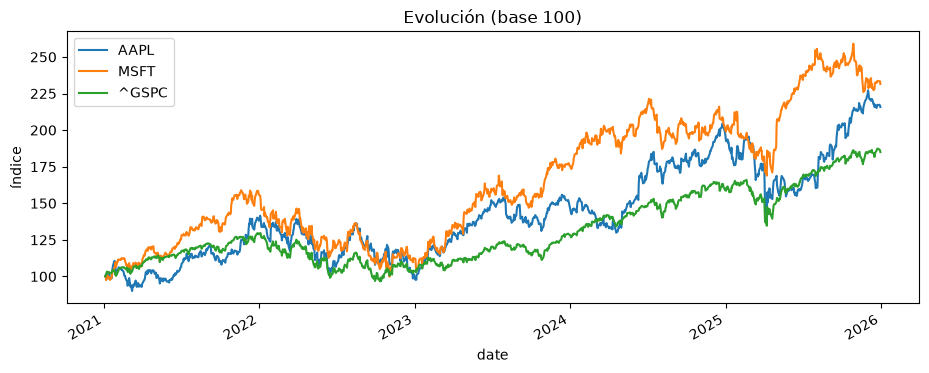

In [5]:
# Precios normalizados a 100 al inicio del periodo
normalized = pd.DataFrame({t: s.prices / s.prices.iloc[0] * 100 for t, s in prices.series.items()})
normalized.plot(title="Evolución (base 100)", ylabel="índice")
plt.show()

## 3. El mismo contrato con otra fuente

Cambiar de fuente es cambiar un nombre: la salida sigue siendo una `PriceSeries` con las
mismas columnas (salvo `adj_close`, que el plan gratuito de Twelve Data no ofrece). El
código de análisis no cambia.

In [6]:
if os.getenv("TWELVE_DATA_API_KEY"):
    other = build_download_service("twelve_data", None).download_prices(
        DownloadRequest(tickers=["AAPL"], start=date(2025, 1, 1), end=date(2025, 12, 31))
    )
    show_errors(other)
    if other.ok:
        td, yf = other.series["AAPL"], prices.series["AAPL"]
        print("Columnas Twelve Data:", list(td.data.columns))
        print("Columnas Yahoo:      ", list(yf.data.columns))
        both = pd.concat(
            {"yahoo": yf.data["close"], "twelve_data": td.data["close"]}, axis=1
        ).dropna()
        print(
            f"\nCierres comparados en {len(both)} sesiones comunes; "
            f"diferencia máxima: {(both['yahoo'] - both['twelve_data']).abs().max():.4f} USD"
        )
else:
    print("Sin TWELVE_DATA_API_KEY en .env: se omite esta sección.")

1 OK, 0 fallidas
Columnas Twelve Data: ['open', 'high', 'low', 'close', 'volume']
Columnas Yahoo:       ['open', 'high', 'low', 'close', 'adj_close', 'volume']

Cierres comparados en 250 sesiones comunes; diferencia máxima: 0.0000 USD


## 4. Series macro sin clave

El BCE usa identificadores SDMX (`<flujo>/<clave>`) y el Banco Mundial
`<país ISO3>/<indicador>`. Ambas devuelven `MacroSeries`, fechadas al **inicio** del
periodo para que se alineen con cualquier otra fuente.

In [7]:
ecb = build_download_service(None, "ecb").download_macro(
    MacroRequest(
        series_ids=["EXR/D.USD.EUR.SP00.A", "ICP/M.U2.N.000000.4.ANR"], start=date(2020, 1, 1)
    )
)
show_errors(ecb)

world_bank = build_download_service(None, "world_bank").download_macro(
    MacroRequest(series_ids=["ESP/NY.GDP.MKTP.CD", "ESP/FP.CPI.TOTL.ZG"], start=date(2000, 1, 1))
)
show_errors(world_bank)

pd.concat([summary(ecb), summary(world_bank)])

2 OK, 0 fallidas
2 OK, 0 fallidas


,fuente,frecuencia,n_obs,inicio,fin,media,std,unidades,vintage
id,,,,,,,,,
EXR/D.USD.EUR.SP00.A,ecb,daily,1755,2020-01-02,2026-11-05,1.117479e+00,5.615489e-02,USD,None
ICP/M.U2.N.000000.4.ANR,ecb,monthly,72,2020-01-01,2025-12-01,3.526389e+00,2.935312e+00,PCCH,None
ESP/NY.GDP.MKTP.CD,world_bank,annual,26,2000-01-01,2025-01-01,1.307121e+12,3.166933e+11,None,None
ESP/FP.CPI.TOTL.ZG,world_bank,annual,26,2000-01-01,2025-01-01,2.388217e+00,1.883266e+00,None,None


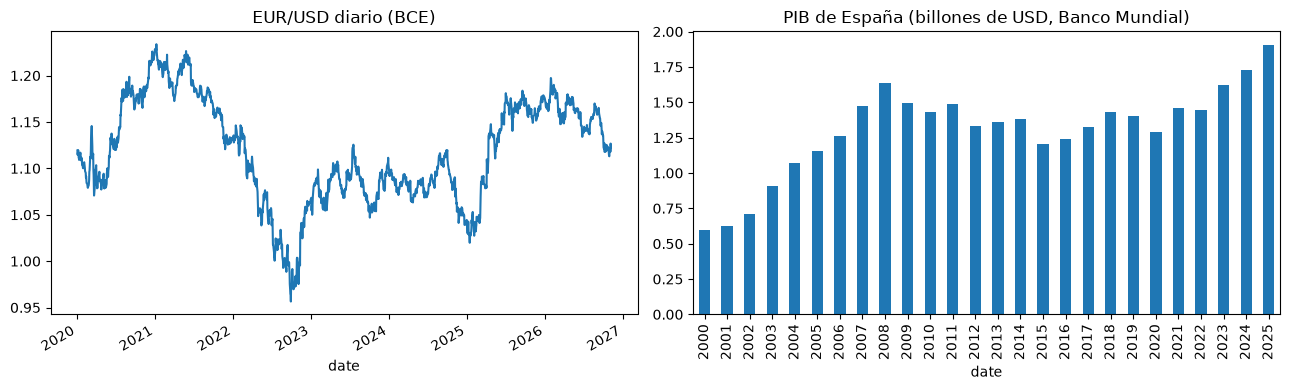

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if "EXR/D.USD.EUR.SP00.A" in ecb.series:
    ecb.series["EXR/D.USD.EUR.SP00.A"].data.plot(ax=axes[0], title="EUR/USD diario (BCE)")
else:
    axes[0].set_title("EUR/USD: el BCE no respondió (ver errores arriba)")
if "ESP/NY.GDP.MKTP.CD" in world_bank.series:
    gdp = world_bank.series["ESP/NY.GDP.MKTP.CD"].data / 1e12
    gdp.index = gdp.index.year
    gdp.plot(ax=axes[1], kind="bar", title="PIB de España (billones de USD, Banco Mundial)")
plt.tight_layout()
plt.show()

## 5. FRED: última revisión frente a vintage

Muchas series macro se **revisan** después de publicarse. Con `as_of`, FRED (vía ALFRED)
devuelve los datos **tal como se conocían ese día**, que es lo que habría visto un
backtest honesto. Comparamos el IPC de EE. UU. de hoy con el publicado a 30/06/2015.

Vintage: 2015-06-30; última observación conocida entonces: 2015-05-01
Meses revisados: 53 de 65


,hoy,publicado_2015-06-30,revisión
date,,,
2015-01-01,234.747,234.677,0.070
2015-02-01,235.342,235.186,0.156
2015-03-01,235.976,235.740,0.236
2015-04-01,236.222,235.982,0.240
2015-05-01,237.001,237.031,-0.030


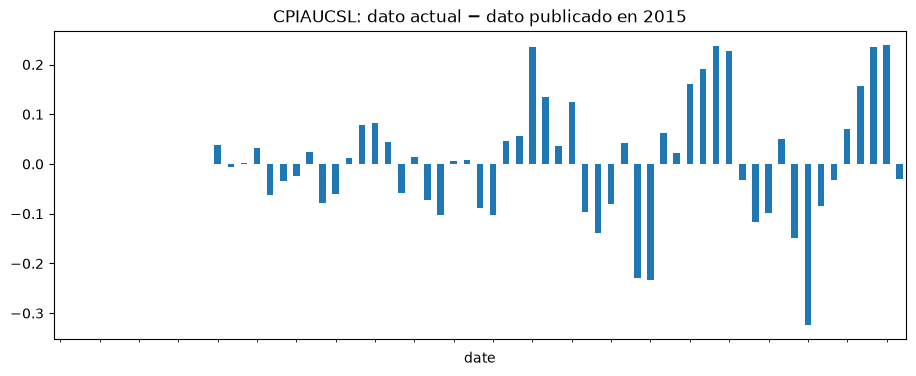

In [9]:
if os.getenv("FRED_API_KEY"):
    fred = build_download_service(None, "fred")
    request = dict(series_ids=["CPIAUCSL"], start=date(2010, 1, 1), end=date(2015, 6, 30))
    latest = fred.download_macro(MacroRequest(**request)).series["CPIAUCSL"]
    vintage = fred.download_macro(MacroRequest(**request, as_of=date(2015, 6, 30))).series[
        "CPIAUCSL"
    ]

    compare = pd.concat({"hoy": latest.data, "publicado_2015-06-30": vintage.data}, axis=1).dropna()
    compare["revisión"] = compare["hoy"] - compare["publicado_2015-06-30"]
    print(f"Vintage: {vintage.vintage}; última observación conocida entonces: {vintage.end}")
    print(f"Meses revisados: {(compare['revisión'].abs() > 1e-9).sum()} de {len(compare)}")
    display(compare.tail())
    compare["revisión"].plot(kind="bar", title="CPIAUCSL: dato actual − dato publicado en 2015")
    plt.xticks([])
    plt.show()
else:
    print("Sin FRED_API_KEY en .env: se omite esta sección.")

## 6. Validación de peticiones

Las peticiones son objetos del dominio que **se validan al crearse**: un error de uso
salta antes de tocar la red.

In [10]:
for label, build in [
    ("lista vacía", lambda: DownloadRequest(tickers=[])),
    (
        "start > end",
        lambda: DownloadRequest(tickers=["AAPL"], start=date(2024, 2, 1), end=date(2024, 1, 1)),
    ),
    ("límite 0", lambda: DocumentRequest(limit=0)),
]:
    try:
        build()
    except InvalidRequestError as exc:
        print(f"{label:<12} → InvalidRequestError: {exc}")

lista vacía  → InvalidRequestError: tickers no puede estar vacío
start > end  → InvalidRequestError: start (2024-02-01) no puede ser posterior a end (2024-01-01)
límite 0     → InvalidRequestError: limit debe ser >= 1 (recibido 0)


## 7. Documentos regulatorios

CNMV y ESMA no publican series sino documentos, así que tienen su propio modelo
(`RegulatoryDocument`) y su propio caso de uso. El RSS de la CNMV solo incluye lo
publicado desde la sesión anterior; ESMA lista los ficheros FIRDS.

In [11]:
def documents_table(source: str, request: DocumentRequest) -> pd.DataFrame:
    try:
        docs = build_document_service(source).list_documents(request)
    except ToolkitError as exc:
        print(f"{source}: {exc}")
        return pd.DataFrame()
    print(f"{source}: {len(docs)} documentos")
    return pd.DataFrame(
        [
            {
                "publicado": d.published_at,
                "id": d.identifier,
                "emisor / tipo": d.issuer or d.category,
                "título": d.title,
            }
            for d in docs
        ]
    )


documents_table("cnmv", DocumentRequest(limit=5))

cnmv: 4 documentos


,publicado,id,emisor / tipo,título
0,2026-11-05 17:57:11,43511,"COX INFRASTRUCTURE GROUP, S.A.","COX INFRASTRUCTURE GROUP, S.A.: Sobre Gobierno..."
1,2026-11-05 17:12:04,43510,"INTERNATIONAL CONSOLIDATED AIRLINES GROUP, S.A.","INTERNATIONAL CONSOLIDATED AIRLINES GROUP, S.A..."
2,2026-11-05 17:06:13,43509,"GESTAMP AUTOMOCION, S.A.","GESTAMP AUTOMOCION, S.A.: Contratos de liquide..."
3,2026-11-05 16:36:41,43508,"COMPAÑIA ESPAÑOLA DE VIVIENDAS EN ALQUILER, S.A.","COMPAÑIA ESPAÑOLA DE VIVIENDAS EN ALQUILER, S...."


In [12]:
documents_table("esma", DocumentRequest("DLTINS", limit=5))

esma: 5 documentos


,publicado,id,emisor / tipo,título
0,2026-11-05,119680,DLTINS,DLTINS_20261105_01of04.zip
1,2026-11-05,119681,DLTINS,DLTINS_20261105_02of04.zip
2,2026-11-05,119682,DLTINS,DLTINS_20261105_03of04.zip
3,2026-11-05,119683,DLTINS,DLTINS_20261105_04of04.zip
4,2026-11-04,119628,DLTINS,DLTINS_20261104_01of04.zip


## 8. Cartera y Monte Carlo

`Portfolio` vive en el dominio: recibe `PriceSeries` de cualquier fuente, valida los
pesos, alinea las fechas comunes y calcula riesgo y retorno **por periodo** (aquí,
diario). La simulación usa un movimiento browniano geométrico.

Los gráficos se hacen aquí, en el notebook: el dominio calcula, no dibuja.

In [13]:
weights = {"AAPL": 0.4, "MSFT": 0.4, "^GSPC": 0.2}
portfolio = Portfolio(series=[prices.series[t] for t in weights], weights=weights)

TRADING_DAYS = 252
print(f"Fechas comunes:        {len(portfolio.returns)}")
annual_return = portfolio.mean_return * TRADING_DAYS
annual_vol = portfolio.volatility * np.sqrt(TRADING_DAYS)
print(f"Retorno medio diario:  {portfolio.mean_return:.5f}  (≈ {annual_return:.1%} anual)")
print(f"Volatilidad diaria:    {portfolio.volatility:.5f}  (≈ {annual_vol:.1%} anual)")
portfolio.returns.corr().round(2)

Fechas comunes:        1254
Retorno medio diario:  0.00074  (≈ 18.6% anual)
Volatilidad diaria:    0.01405  (≈ 22.3% anual)


,AAPL,MSFT,^GSPC
AAPL,1.00,0.63,0.76
MSFT,0.63,1.00,0.76
^GSPC,0.76,0.76,1.00


Valor inicial:        100
Mediana a 1 año:      116.5
Percentil 5 (VaR 95): 80.9  → pérdida de 19.1
Probabilidad de pérdida: 23.5%


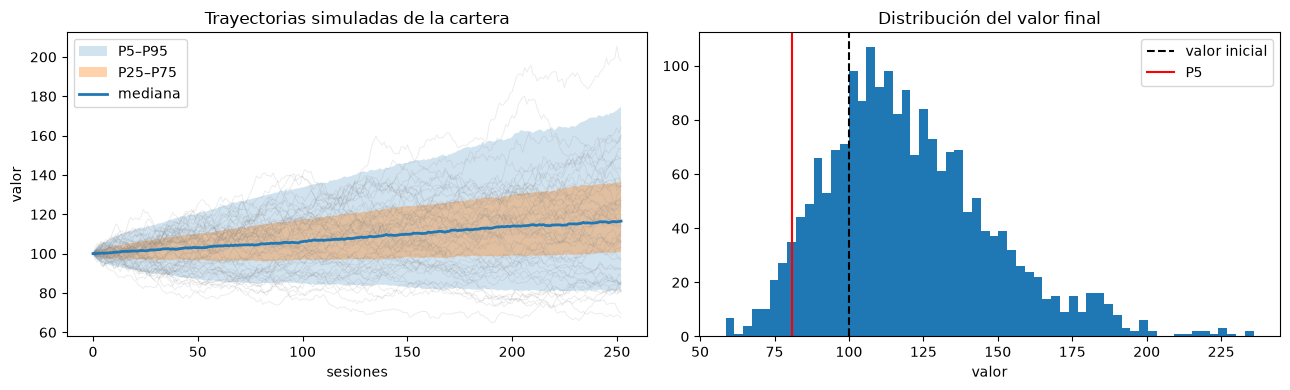

In [14]:
sim = portfolio.monte_carlo(n_steps=TRADING_DAYS, n_simulations=2000, initial_value=100.0, seed=42)

print(f"Valor inicial:        {sim.initial_value:.0f}")
print(f"Mediana a 1 año:      {sim.quantile(0.50):.1f}")
print(
    f"Percentil 5 (VaR 95): {sim.quantile(0.05):.1f}  → pérdida de {100 - sim.quantile(0.05):.1f}"
)
print(f"Probabilidad de pérdida: {sim.prob_loss:.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
bands = np.percentile(sim.paths, [5, 25, 50, 75, 95], axis=1)
steps = np.arange(sim.paths.shape[0])
ax1.plot(sim.paths[:, :50], color="grey", alpha=0.15, linewidth=0.7)
ax1.fill_between(steps, bands[0], bands[4], alpha=0.2, label="P5–P95")
ax1.fill_between(steps, bands[1], bands[3], alpha=0.35, label="P25–P75")
ax1.plot(steps, bands[2], linewidth=2, label="mediana")
ax1.set(title="Trayectorias simuladas de la cartera", xlabel="sesiones", ylabel="valor")
ax1.legend()
ax2.hist(sim.final_values, bins=60)
ax2.axvline(sim.initial_value, color="black", linestyle="--", label="valor inicial")
ax2.axvline(sim.quantile(0.05), color="red", label="P5")
ax2.set(title="Distribución del valor final", xlabel="valor")
ax2.legend()
plt.tight_layout()
plt.show()

In [15]:
# Un único activo, partiendo de su último precio real
sim_aapl = portfolio.monte_carlo_asset("AAPL", n_steps=TRADING_DAYS, n_simulations=2000, seed=7)
print(
    f"AAPL hoy: {sim_aapl.initial_value:.2f} USD · mediana a 1 año: {sim_aapl.quantile(0.5):.2f} · "
    f"P5: {sim_aapl.quantile(0.05):.2f} · P(pérdida): {sim_aapl.prob_loss:.1%}"
)

AAPL hoy: 271.12 USD · mediana a 1 año: 315.69 · P5: 202.94 · P(pérdida): 29.1%


## 9. Guardar y releer las series

`StoreSeries` guarda cada serie en un fichero. El notebook no sabe cómo se escriben: si
mañana el destino fuera una base de datos, solo cambiaría `build_storage_service`.

In [16]:
out_dir = Path(tempfile.mkdtemp(prefix="toolkit_demo_"))
storage = build_storage_service(out_dir, "csv")

saved = storage.store(prices.series) + storage.store(world_bank.series)
for location in saved:
    print("guardado:", Path(location).relative_to(out_dir))

# Releer y comprobar que el fichero conserva la serie
reloaded = pd.read_csv(out_dir / "AAPL.csv", index_col="date", parse_dates=True)
pd.testing.assert_frame_equal(
    reloaded, prices.series["AAPL"].data, check_freq=False, check_index_type=False
)
print("\nAAPL.csv releído: idéntico a la PriceSeries original ✓")
reloaded.head(3)

guardado: AAPL.csv
guardado: MSFT.csv
guardado: _GSPC.csv
guardado: ESP_NY.GDP.MKTP.CD.csv
guardado: ESP_FP.CPI.TOTL.ZG.csv

AAPL.csv releído: idéntico a la PriceSeries original ✓


,open,high,low,close,adj_close,volume
date,,,,,,
2021-01-04,133.520004,133.610001,126.760002,129.410004,125.632523,143301900.0
2021-01-05,128.889999,131.740005,128.429993,131.009995,127.185822,97664900.0
2021-01-06,127.720001,131.050003,126.379997,126.599998,122.904533,155088000.0


## 10. La misma descarga desde la CLI

La CLI es otro adaptador de entrada sobre los mismos casos de uso. `python -m toolkit`
equivale al comando `toolkit`.

In [17]:
cli_dir = out_dir / "cli"
completed = subprocess.run(
    [
        sys.executable,
        "-m",
        "toolkit",
        "prices",
        "AAPL",
        "^GSPC",
        "NOEXISTE123",
        "--start",
        "2025-01-01",
        "--end",
        "2025-12-31",
        "--out",
        str(cli_dir),
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
)
print(completed.stdout.replace(str(out_dir), "<out_dir>"))
print("código de salida:", completed.returncode, "(0 = al menos una serie OK)")

Descargadas: 2 OK, 1 fallidas
ticker      fuente        divisa   n_obs  inicio     fin           media_ret    std_ret
AAPL        yahoo         USD        250  2025-01-02 2025-12-31     0.000661   0.020450
^GSPC       yahoo         USD        250  2025-01-02 2025-12-31     0.000688   0.011835
Errores:
  NOEXISTE123: yahoo: sin datos para NOEXISTE123 en el rango solicitado
  guardado: <out_dir>\cli\AAPL.csv
  guardado: <out_dir>\cli\_GSPC.csv

código de salida: 0 (0 = al menos una serie OK)


## Resumen

- Se han usado **cinco fuentes de datos reales** y dos regulatorias sin importar ni un
  solo adaptador: todo pasa por los casos de uso de `bootstrap`.
- Todas las fuentes entregan los **mismos objetos** (`PriceSeries`, `MacroSeries`,
  `RegulatoryDocument`), así que la cartera y Monte Carlo funcionan con cualquiera.
- Los fallos de una serie (un ticker inexistente, una API que no responde) **no tumban
  el lote**, y las peticiones inválidas se rechazan antes de llamar a la red.
- Guardar es otro caso de uso: la CLI y este notebook comparten la misma implementación.

La arquitectura completa está en [`docs/architecture.md`](../docs/architecture.md).